# Credit Card Fraud Detection

This notebook explores the `card_transdata.csv` dataset to understand how fraudulent transactions differ from legitimate ones, then compares a naive "never fraud" baseline with a **K-Nearest Neighbors (KNN)** classifier built with scikit-learn.

**Dataset columns**

| Column | Type | Description |
|---|---|---|
| `distance_from_home` | continuous | Distance from home where the transaction happened |
| `distance_from_last_transaction` | continuous | Distance from where the last transaction happened |
| `ratio_to_median_purchase_price` | continuous | Purchase price divided by the cardholder's median purchase price |
| `repeat_retailer` | binary | Transaction happened at a retailer used before |
| `used_chip` | binary | Transaction used the card's chip |
| `used_pin_number` | binary | Transaction used a PIN number |
| `online_order` | binary | Transaction was an online order |
| `fraud` | binary (target) | 1 = fraudulent, 0 = legitimate |

**Outline**
1. Setup and data loading
2. Data quality checks
3. Exploratory analysis: count plots, histograms, scatter plots, fraud breakdown for the binary features
4. Modeling: "never fraud" baseline vs KNN (k = 3)
5. Conclusions

## AI assistance

This notebook was built with the help of AI:

- **AI system:** Claude Code (Anthropic's AI coding assistant), running in the VS Code extension
- **AI model / version:** Claude Opus 5.5 (model ID `claude-opus-5-5`)

The notebook went through three main rounds of prompts. The key prompts are quoted in boxes like the one below, placed right before the part of the notebook they produced. Smaller back-and-forth tweaks are left out.

**AI prompt used (Prompt 1 of 3, the original request):**

> Write a Python notebook titled Credit Card Fraud Detection that loads the card_transdata.csv file from the current folder using pandas.
> Explore and visualize the dataset to better understand the differences between fraudulent and non-fraudulent transactions.
> Also, create additional visualizations that help explain how fraudulent and non-fraudulent transactions break down across each variable in the dataset. The goal is to identify patterns and relationships that may help distinguish fraudulent transactions from legitimate ones.
> Finally, use scikit-learn to build and evaluate a K-Nearest Neighbors (KNN) classification model that predicts whether a transaction is fraudulent or non-fraudulent. Include the necessary data preprocessing, train-test split, model training, and evaluation metrics to assess the model's performance.

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# Green for non-fraud, red for fraud, used in every plot
NON_FRAUD_COLOR = "#2ca02c"
FRAUD_COLOR = "#d62728"
FRAUD_PALETTE = {0: NON_FRAUD_COLOR, 1: FRAUD_COLOR}
# Blue/orange for the 0/1 values of a feature in plots that don't split by fraud
VALUE_PALETTE = {0: "#1f77b4", 1: "#ff7f0e"}
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("card_transdata.csv")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 999   Columns: 8


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.878,0.311,1.946,1.000,1.000,0.000,0.000,0
1,10.830,0.176,1.294,1.000,NaN,0.000,0.000,0
2,5.091,NaN,0.428,1.000,0.000,0.000,1.000,0
3,2.248,5.600,0.363,1.000,1.000,0.000,1.000,0
4,44.191,0.566,2.223,1.000,1.000,0.000,1.000,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


## 2. Data quality checks

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum()}")
quality

Duplicate rows: 0
Rows with at least one missing value: 22


,dtype,missing,missing_%,unique_values
distance_from_home,float64,0,0.000,999
distance_from_last_transaction,float64,3,0.300,996
ratio_to_median_purchase_price,float64,2,0.200,997
repeat_retailer,float64,7,0.700,2
used_chip,float64,4,0.400,2
used_pin_number,float64,2,0.200,2
online_order,float64,4,0.400,2
fraud,int64,0,0.000,2


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_from_home,999.000,26.877,63.900,0.104,3.991,10.340,25.394,965.911
distance_from_last_transaction,996.000,5.437,35.668,0.001,0.306,0.959,3.137,990.070
ratio_to_median_purchase_price,997.000,1.655,2.351,0.017,0.468,0.956,1.922,36.074
repeat_retailer,992.000,0.892,0.310,0.000,1.000,1.000,1.000,1.000
used_chip,995.000,0.314,0.464,0.000,0.000,0.000,1.000,1.000
used_pin_number,997.000,0.117,0.322,0.000,0.000,0.000,0.000,1.000
online_order,995.000,0.673,0.469,0.000,0.000,1.000,1.000,1.000
fraud,999.000,0.079,0.270,0.000,0.000,0.000,0.000,1.000


**Observations**
- A handful of values are missing in most feature columns (less than 1% per column). The plots below simply skip missing values, and the rows with missing values are dropped before modeling in Section 4.
- The three distance/price features are heavily **right-skewed**: their maximum values are far larger than their 75th percentiles.

## 3. Exploratory data analysis

### 3.1 Count plots

**AI prompt used (Prompt 3 of 3, excerpt):**

> Change the plots to a simpler style using seaborn, with green for non-fraud and red for fraud everywhere. Make the class distribution a plain countplot of fraud, and add plain countplots for used_pin_number, repeat_retailer, and online_order.

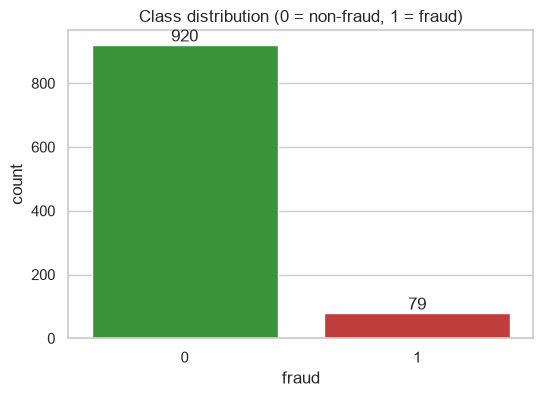

fraud
0   92.100
1    7.900
Name: percent, dtype: float64


In [6]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="fraud", hue="fraud", palette=FRAUD_PALETTE, legend=False)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Class distribution (0 = non-fraud, 1 = fraud)")
plt.show()

print(df["fraud"].value_counts(normalize=True).mul(100).round(1).rename("percent"))

The dataset is **imbalanced**: only about 8% of transactions are fraudulent. A model that always predicts "non-fraud" would already be about 92% accurate, so accuracy alone is a misleading metric. Section 4 shows this directly.

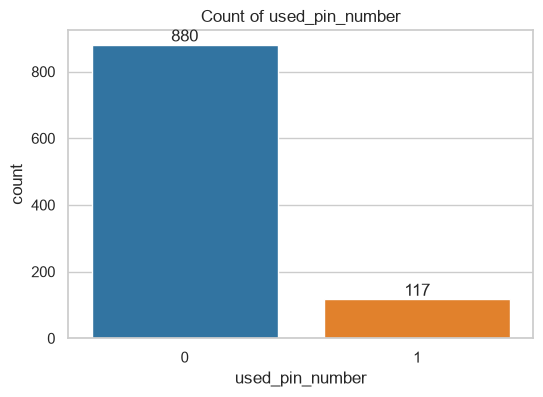

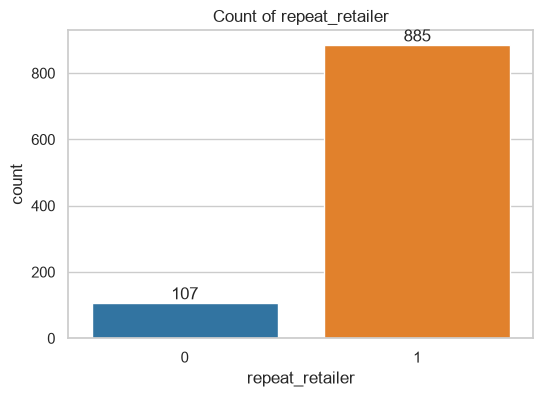

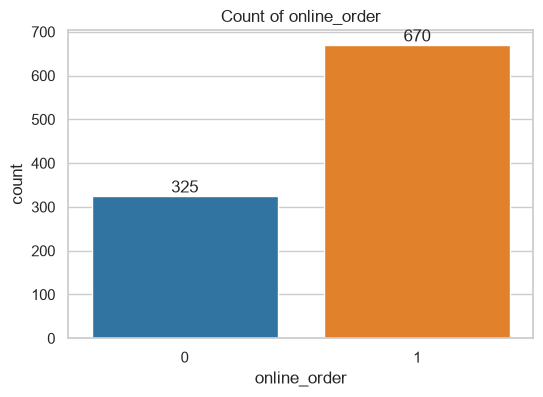

In [7]:
def without_missing(col):
    """Rows where col is present, with col as int so axis labels read 0/1 instead of 0.0/1.0."""
    return df.dropna(subset=[col]).astype({col: int})

for col in ["used_pin_number", "repeat_retailer", "online_order"]:
    plt.figure(figsize=(6, 4))
    ax = sns.countplot(data=without_missing(col), x=col, hue=col, palette=VALUE_PALETTE, legend=False)
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_title(f"Count of {col}")
    plt.show()

- **`used_pin_number`**: most transactions (about 88%) do not use a PIN.
- **`repeat_retailer`**: most transactions (about 89%) are at a retailer the cardholder has used before.
- **`online_order`**: about two thirds of transactions are online orders.

### 3.2 Histograms

**AI prompt used (Prompts 2 and 3, excerpts):**

> Then add a graph showing the distribution of ratio_to_median_purchase_price, along with bar charts for each variable that clearly show how fraudulent and non-fraudulent transactions break down, so we can see which variables matter most for identifying fraud.
>
> Make the ratio_to_median_purchase_price distribution a single histogram with 30 bins instead of two panels, and add the same kind of histogram for distance_from_home.

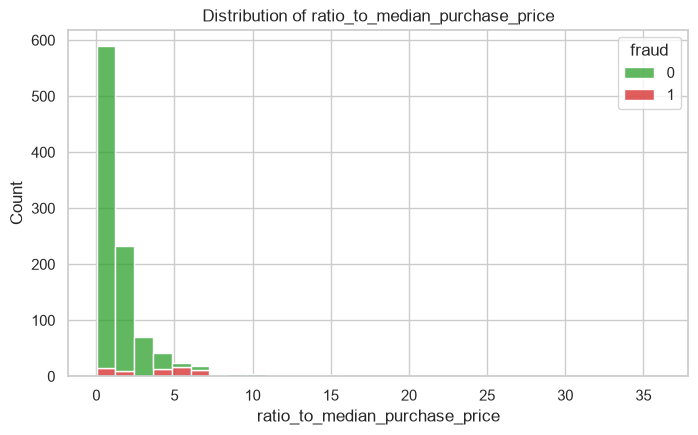

In [8]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x="ratio_to_median_purchase_price", bins=30,
             hue="fraud", palette=FRAUD_PALETTE, multiple="stack")
plt.title("Distribution of ratio_to_median_purchase_price")
plt.show()

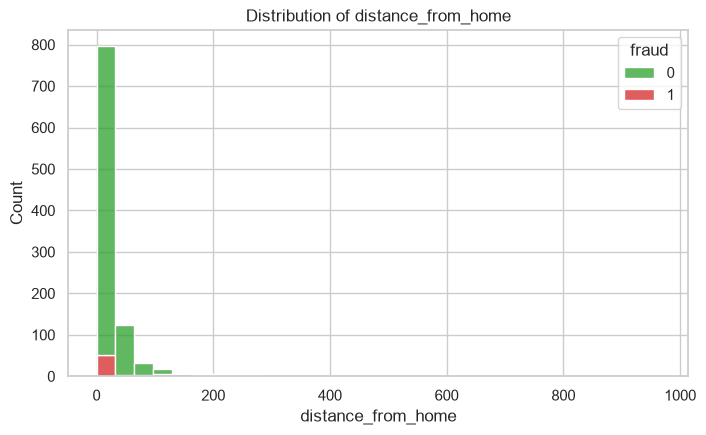

In [9]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x="distance_from_home", bins=30,
             hue="fraud", palette=FRAUD_PALETTE, multiple="stack")
plt.title("Distribution of distance_from_home")
plt.show()

Both features are strongly **right-skewed**: most transactions are close to home and close to the cardholder's usual purchase size (ratio around 1), with a long tail of much larger values. In the `ratio_to_median_purchase_price` histogram, fraud (red) is only a thin slice of the tall bars near 0-2 but makes up a large share of the bars between roughly 4 and 7, so unusually large purchases are much more likely to be fraud. In the `distance_from_home` histogram, the tail bars are too short to read; the scatter plots below show the far-from-home transactions more clearly.

### 3.3 Scatter plots: purchase-price ratio vs distance

**AI prompt used (Prompts 2 and 3, excerpts):**

> Also create two separate scatter plots, both with ratio_to_median_purchase_price on the y-axis: one with distance_from_home on the x-axis and one with distance_from_last_transaction on the x-axis, with points colored by fraud vs non-fraud.
>

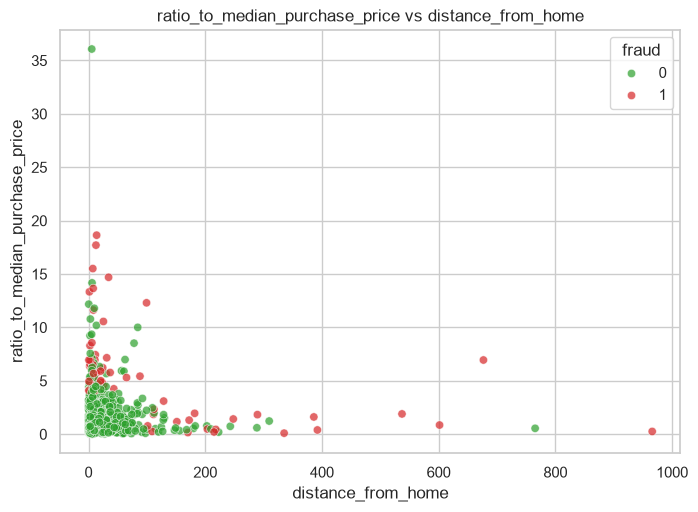

In [77]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x="distance_from_home", y="ratio_to_median_purchase_price",
                hue="fraud", palette=FRAUD_PALETTE, alpha=0.7)
plt.title("ratio_to_median_purchase_price vs distance_from_home")
plt.show()

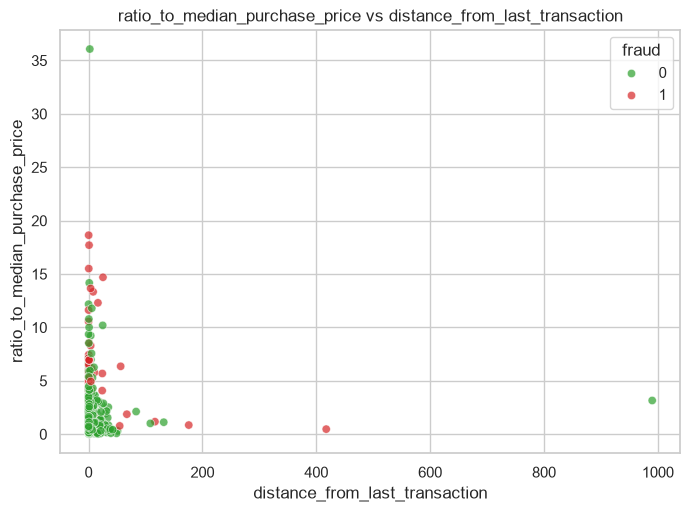

In [78]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x="distance_from_last_transaction", y="ratio_to_median_purchase_price",
                hue="fraud", palette=FRAUD_PALETTE, alpha=0.7)
plt.title("ratio_to_median_purchase_price vs distance_from_last_transaction")
plt.show()

With normal (linear) axes, most points are packed into the bottom-left corner because of the skew, but the fraud pattern is still visible:
- **vs `distance_from_home`**: the red fraud points stand out above the main cluster (unusually large purchases) and toward the right (transactions far from home).
- **vs `distance_from_last_transaction`**: fraud is again separated vertically by purchase size, but it is not pushed toward the right, so distance from the last transaction adds less information.

### 3.4 Binary features: fraud breakdown

For `used_pin_number`, `used_chip`, and `online_order`, there are two plots each:
1. A **count plot** split by fraud, showing the number of fraud and non-fraud transactions when the flag is 0 and 1.
2. A **stacked percentage bar chart**, showing what percent of transactions are fraud vs non-fraud when the flag is 0 and when it is 1.

**AI prompt used (Prompts 2 and 3, excerpts):**

> take the binary features out of the combined by class graph and put them in their own separate graph.
>
> For used_pin_number, used_chip, and online_order, replace the two-panel charts with two separate plots each: a countplot with hue='fraud', then a stacked percentage bar chart showing the % fraud vs non-fraud for 0 and 1.

In [12]:
# Summary table of fraud rate when each flag is 0 vs 1
binary_cols = ["repeat_retailer", "used_chip", "used_pin_number", "online_order"]
summary = []
for col in binary_cols:
    for val in (0, 1):
        sub = df[df[col] == val]
        summary.append({"feature": col, "value": val, "transactions": len(sub),
                        "fraud_cases": int(sub["fraud"].sum()),
                        "fraud_rate_%": sub["fraud"].mean() * 100})
pd.DataFrame(summary)

,feature,value,transactions,fraud_cases,fraud_rate_%
0,repeat_retailer,0,107,6,5.607
1,repeat_retailer,1,885,72,8.136
2,used_chip,0,683,65,9.517
3,used_chip,1,312,13,4.167
4,used_pin_number,0,880,79,8.977
5,used_pin_number,1,117,0,0.000
6,online_order,0,325,2,0.615
7,online_order,1,670,76,11.343


In [13]:
def fraud_countplot(col):
    plt.figure(figsize=(7, 4.5))
    ax = sns.countplot(data=without_missing(col), x=col, hue="fraud", palette=FRAUD_PALETTE)
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_title(f"{col}: fraud vs non-fraud counts")
    plt.show()

def fraud_percent_bar(col):
    data = without_missing(col)
    pct = pd.crosstab(data[col], data["fraud"], normalize="index") * 100
    ax = pct.plot(kind="bar", stacked=True, color=[NON_FRAUD_COLOR, FRAUD_COLOR], figsize=(7, 4.5), rot=0)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.1f}%" if v > 0 else "" for v in container.datavalues],
                     label_type="center", color="white", fontweight="bold")
    ax.set_ylabel("% of transactions")
    ax.set_ylim(0, 100)
    ax.set_title(f"{col}: % fraud vs non-fraud")
    ax.legend(title="fraud", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

#### `used_pin_number`

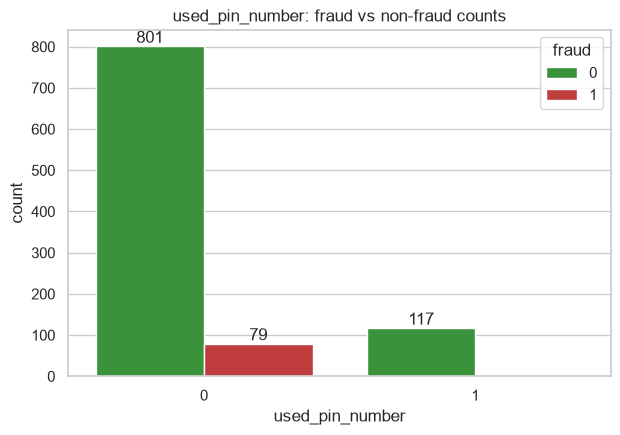

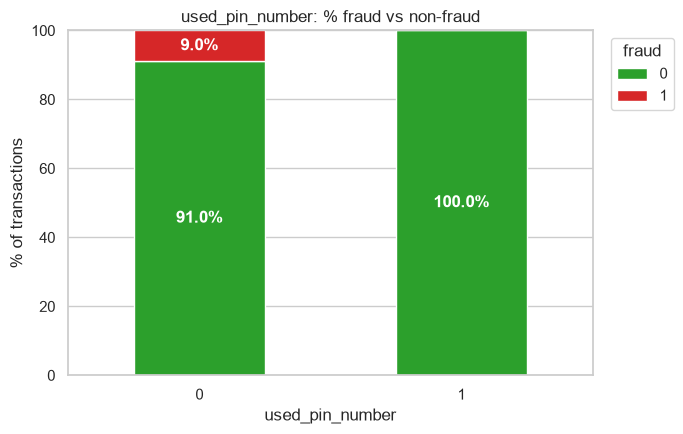

In [14]:
fraud_countplot("used_pin_number")
fraud_percent_bar("used_pin_number")

#### `used_chip`

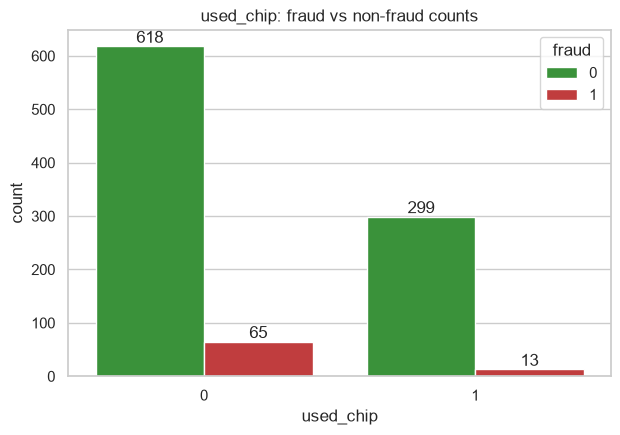

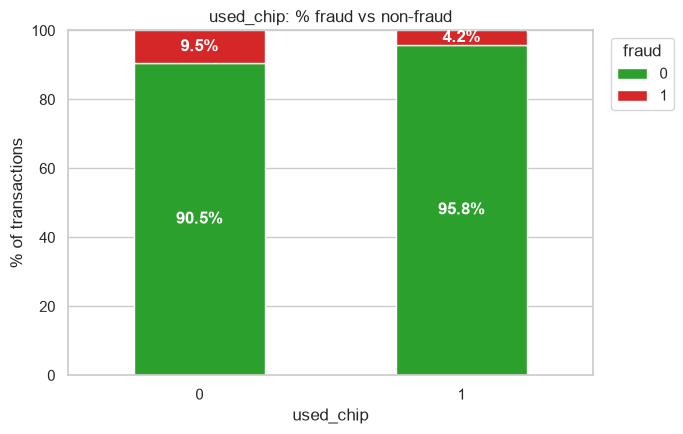

In [15]:
fraud_countplot("used_chip")
fraud_percent_bar("used_chip")

#### `online_order`

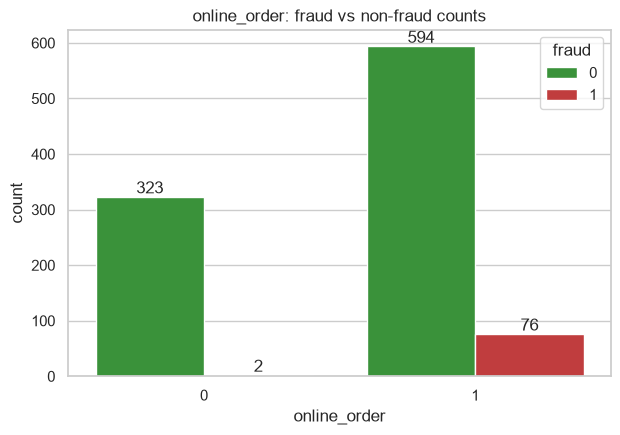

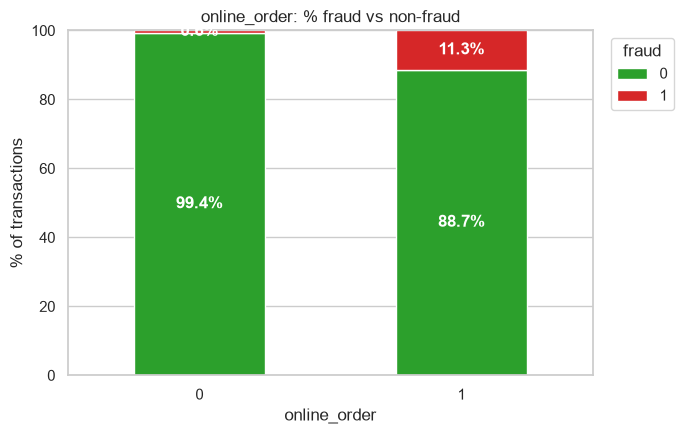

In [16]:
fraud_countplot("online_order")
fraud_percent_bar("online_order")

**Observations**
- **`used_pin_number`**: none of the transactions that used a PIN were fraudulent. A PIN is strong evidence that the real cardholder was present.
- **`used_chip`**: chip transactions have a lower fraud rate (about 4%) than non-chip transactions (about 10%).
- **`online_order`**: almost all fraud happens online. Online orders have a fraud rate of about 11%, compared with under 1% for in-person transactions.
- **`repeat_retailer`** (see the summary table): the fraud rate is similar whether or not the retailer was used before, so it carries little information on its own.

## 4. Modeling

### 4.1 Data preparation and train/test split (80% / 20%)

- Rows with any missing value are **dropped** (they are a small share of the data).
- The KNN model is trained on the **raw features with no scaling**.
- The split is **stratified** so the training and test sets both keep the ~8% fraud rate.

**AI prompt used (Prompts 2 and 3, excerpts):**

> For modeling, scrap all the models you created before and start fresh. Split the data into 80% training and 20% testing. First, build a baseline "never fraud" model that always predicts not fraud, and evaluate it with a confusion matrix. Then build a KNN model with k = 3 and evaluate it with a confusion matrix as well.
>
> For modeling, drop rows with missing values instead of imputing, and train KNN (k=3) on the raw features with no scaling. Show each confusion matrix as a seaborn heatmap with the counts on it and the accuracy % in the title, using Reds for the never fraud model and Blues for KNN.

In [17]:
model_df = df.dropna()
print(f"Rows before: {len(df)}   Rows after dropping missing values: {len(model_df)}   "
      f"(dropped {len(df) - len(model_df)})")

X = model_df.drop(columns="fraud")
y = model_df["fraud"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {len(X_train)} rows, {y_train.sum()} fraud ({y_train.mean():.2%})")
print(f"Test set:     {len(X_test)} rows, {y_test.sum()} fraud ({y_test.mean():.2%})")

Rows before: 999   Rows after dropping missing values: 977   (dropped 22)
Training set: 781 rows, 61 fraud (7.81%)
Test set:     196 rows, 15 fraud (7.65%)


In [18]:
def plot_confusion(y_true, y_pred, title, cmap):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    acc = accuracy_score(y_true, y_pred)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False,
                xticklabels=["Non-fraud", "Fraud"], yticklabels=["Non-fraud", "Fraud"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{title}\nAccuracy: {acc:.1%}")
    plt.show()

### 4.2 Baseline: "never fraud" model

This model ignores the features and always predicts the most common class, "non-fraud". It sets the bar any real model has to beat.

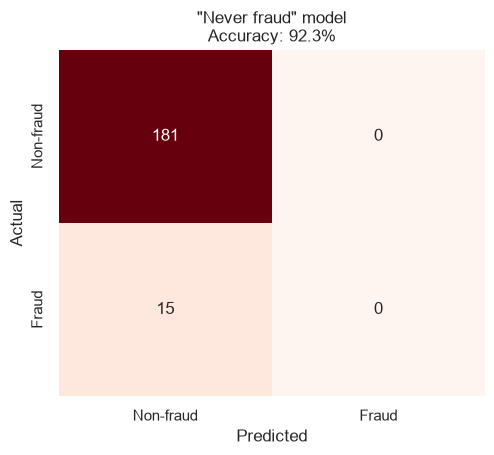

In [19]:
never_fraud = DummyClassifier(strategy="most_frequent")
never_fraud.fit(X_train, y_train)
y_pred_never = never_fraud.predict(X_test)

plot_confusion(y_test, y_pred_never, '"Never fraud" model', cmap="Reds")

The baseline classifies every non-fraud transaction correctly, so its accuracy looks high, but it **misses every single fraud case**.

### 4.3 KNN model (k = 3)

KNN labels a transaction by looking at the 3 most similar transactions in the training set and taking a majority vote.

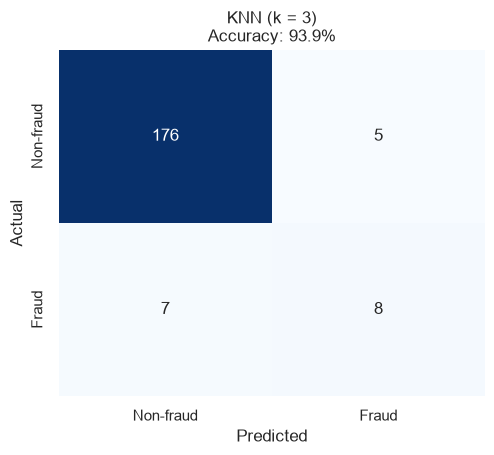

In [20]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

plot_confusion(y_test, y_pred_knn, "KNN (k = 3)", cmap="Blues")

In [21]:
print(classification_report(y_test, y_pred_knn, target_names=["Non-fraud", "Fraud"], digits=3))

              precision    recall  f1-score   support

   Non-fraud      0.962     0.972     0.967       181
       Fraud      0.615     0.533     0.571        15

    accuracy                          0.939       196
   macro avg      0.789     0.753     0.769       196
weighted avg      0.935     0.939     0.937       196



Because the features are not scaled, KNN measures similarity mostly by the features with the largest numbers (`distance_from_home` and `distance_from_last_transaction`, which can reach the hundreds). The 0/1 flags, such as `online_order` and `used_pin_number`, barely affect the distance even though the EDA showed they are strong fraud signals.

### 4.4 Comparing the two models

- **Accuracy**: share of all transactions classified correctly (misleading when fraud is rare).
- **Precision**: of the transactions flagged as fraud, how many really were fraud.
- **Recall**: of the actual fraud cases, how many were caught.
- **F1 score**: balance of precision and recall.

**AI prompt used (Prompts 2 and 3, excerpts):**

> Finally, create a bar chart comparing the performance of both models using accuracy, precision, recall, F1 score, and any other metrics that are useful for comparing fraud detection models.
>
> Make the comparison chart a grouped bar chart with just accuracy, precision, recall, and F1, using blue for KNN, red for never fraud, and a y-axis from 0 to 1.

In [22]:
def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1 score": f1_score(y_true, y_pred, zero_division=0),
    }

comparison = pd.DataFrame({
    "Never fraud": scores(y_test, y_pred_never),
    "KNN (k = 3)": scores(y_test, y_pred_knn),
})
comparison

,Never fraud,KNN (k = 3)
Accuracy,0.923,0.939
Precision,0.000,0.615
Recall,0.000,0.533
F1 score,0.000,0.571


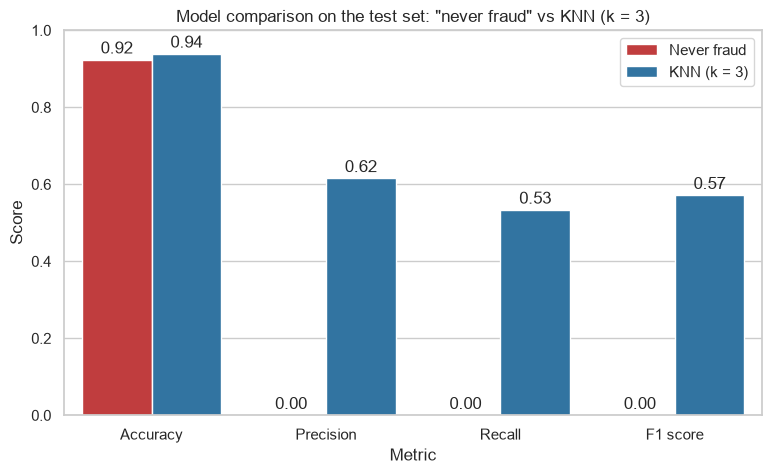

In [23]:
plot_df = comparison.reset_index(names="Metric").melt(id_vars="Metric", var_name="Model", value_name="Score")

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model",
                 palette={"Never fraud": "#d62728", "KNN (k = 3)": "#1f77b4"})
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
ax.set_ylim(0, 1)
ax.set_title('Model comparison on the test set: "never fraud" vs KNN (k = 3)')
ax.legend(loc="upper right")
plt.show()

The comparison makes the accuracy trap clear: the "never fraud" model's accuracy is high only because about 92% of transactions are non-fraud. Its precision, recall and F1 are all zero because it never flags anything.

KNN's accuracy is only slightly higher than the baseline's, but it is the only model that finds any fraud. It still misses a large share of the fraud cases (see recall), and some of its fraud alerts are false alarms (see precision). A likely reason is the lack of scaling described above: the strong 0/1 signals like `online_order` and `used_pin_number` have almost no influence on which neighbors KNN picks.

Keep in mind that the test set has only about 15 fraud cases, so catching or missing a single one moves recall by several percentage points.

## 5. Conclusions

**What distinguishes fraud from non-fraud transactions**
- **Purchase size relative to the cardholder's norm** (`ratio_to_median_purchase_price`): fraud stands out as unusually large purchases.
- **Online orders** account for almost all fraud in this data.
- **PIN use** is strongly protective: no transaction that used a PIN was fraudulent. **Chip use** is also associated with less fraud.
- **Distance from home** is higher for fraud. Distance from the last transaction and repeat-retailer status add little on their own.

**Model performance**
- The "never fraud" model shows why accuracy is misleading for rare events: it is about 92% accurate yet catches no fraud at all.
- KNN (k = 3) on the raw features beats the baseline on precision, recall and F1, but still misses a large share of the fraud.

**Possible next steps**
- Scale the features (for example with `StandardScaler`) so the 0/1 flags count as much as the distance features in KNN's distance calculation.
- Try other values of *k* with cross-validation.